In [170]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from segmentiq.data import get_data

In [171]:
root = Path.cwd().parents[0].resolve()
raw_path = root / Path("data/raw/Online Retail.xlsx")
cache_path = root / Path("data/cache/retail.parquet")

In [172]:
df = get_data(raw_path, cache_path)

.xlsx = 30 seconds / parquet = 0.133 seconds

In [173]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [174]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 59.5 MB


In [175]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [176]:
df.duplicated().sum()

np.int64(5268)

In [177]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


We can see few things with this dataset. Firstly ,CustomerID is float we need to transform it into int.Secondly this dataset has missing values even tough data dictionary says opposite. In addition to missing values dataset has duplicates. And Finally from describe we can see negative values in unitprice and quantity columns. Before deletion in next pr i want to investigate this problems.

In [178]:
missing_customer = df[df["CustomerID"].isna()]
missing_customer.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [179]:
missing_customer.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,135080.000000,135080,135080.000000,0.0
mean,1.995573,2011-06-16 03:03:12.611637,8.076577,NaN
min,-9600.000000,2010-12-01 11:52:00,-11062.060000,NaN
25%,1.000000,2011-02-21 18:10:00,1.630000,NaN
50%,1.000000,2011-06-27 15:27:00,3.290000,NaN
75%,3.000000,2011-10-11 16:37:00,5.450000,NaN
max,5568.000000,2011-12-09 10:26:00,17836.460000,NaN
std,66.696153,NaN,151.900816,NaN


In [180]:
missing_customer["StockCode"].value_counts()

StockCode
DOT       694
85099B    497
21931     414
22411     388
20712     372
         ... 
23017       1
23465       1
23556       1
47591b      1
84859B      1
Name: count, Length: 3810, dtype: int64

We can see that data without customerID is similar to the default data. Both of they have POST stock code for dotcom postage so they do not need customerId and i think they do not need to participate in our RFM analysis. also statistics are similar so i think there are missing values because of the guest purchases. However, in order to perform RFM clustering we need Customer ID to group by. Thus, i will drop missing rows for this column.

Also what i found is strange stock codes as S M POST DOT m Amazon FEE bank charge etc ... I will drop them cause they dont help with analysis and will only harm it. This codes refer to shipping prices and other fees not real orders.

In [181]:
customer = df[~df["CustomerID"].isna()]
customer.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [182]:
customer.duplicated().sum()

np.int64(5225)

Also by deleting all the rows without customerID strange rows with no description was also deleted so now we have clean dataset i will use to perform further EDA.However, duplicates remained in our dataset.To start with, I want to finish what i started with stockcodes for business operations that i will drop.

In [183]:
customer["StockCode"].value_counts().sort_index(ascending=False)

StockCode
POST      1196
PADS         4
M          465
DOT         16
D           77
          ... 
10124A       5
10123C       3
10120       30
10080       21
10002       49
Name: count, Length: 3684, dtype: int64

In [184]:
CODES = ["POST", "PADS", "M", "DOT", "D", "CRUK", "C2", "BANK CHARGES"]
print(customer[customer["StockCode"] == "AMAZONFEE"].shape)

(0, 8)


In [185]:
df.loc[df["StockCode"].isin(CODES), ["StockCode", "Description"]].drop_duplicates()

,StockCode,Description
45,POST,POSTAGE
141,D,Discount
1423,C2,CARRIAGE
1814,DOT,DOTCOM POSTAGE
2239,M,Manual
4406,BANK CHARGES,Bank Charges
52262,POST,NaN
136537,DOT,NaN
157195,PADS,PADS TO MATCH ALL CUSHIONS
317508,CRUK,CRUK Commission


CODES = ["POST","M","DOT","D","CRUK","C2","BANK CHARGES"] In clean dataset there is no AMAZONFEE but other codes exists. Also pads is a real product that they sell so i wont drop it. Other codes are not products so i will drop them.

Now i want to look at the duplicates

In [186]:
dup = customer[customer.duplicated(keep=False)]
dup.sort_values(["InvoiceNo", "StockCode", "Quantity"]).head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


Okay we can see that all duplicates are just same entries of one raw. Its safe to drop them in next PR.

Now let's look at the negative values

In [187]:
negative_quantity = customer[customer["Quantity"] <= 0]
negative_quantity

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In data dictionary we can see that invoice which start with "C" - means cancellation. I want to see if all canceled invoices have negative quantity

In [188]:
print(f"number of negative quantity rows:{negative_quantity.shape[0]}")
print(
    f"number of negative quantity rows where invoice was canceled: {negative_quantity[negative_quantity['InvoiceNo'].str[0] == 'C'].shape[0]}"
)

number of negative quantity rows:8905
number of negative quantity rows where invoice was canceled: 8905


In [189]:
customer[(customer["Quantity"] <= 0) & (customer["UnitPrice"] <= 0)].shape

(0, 8)

They are the same rows so all negative quantity rows are just cancellation we can drop them but it will be a mistake cause canceled order will give false monetary value for many customers.I will subscribe them in order to not face this problem. Also there is no rows with both negative unit price and quantity.

Last thing to check is negative unit price

In [190]:
negative_price = customer[customer["UnitPrice"] < 0]
print(f"number of rows where unitprice is less than 0: {negative_price.shape[0]}")
print(
    f"number of rows where unitprice = 0: {customer[customer['UnitPrice'] == 0].shape[0]}"
)

number of rows where unitprice is less than 0: 0
number of rows where unitprice = 0: 40


We can see that after deletion of missing values in CustomerID there are no more observations where price < 0. Now we only have rows with price = zero that strange

In [191]:
customer[customer["UnitPrice"] == 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


Okay i think that price of zero is possible and is caused by some sort of promo actions or gifts and replacement of the product so i will keep them.

I think with strange unreal observations we have ended so now i will move on to the distributions of the price and quantity in order to find outliers in useful columns.

In [192]:
customer.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,406829.000000,406829,406829.000000,406829.000000
mean,12.061303,2011-07-10 16:30:57.879207,3.460471,15287.690570
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13953.000000
50%,5.000000,2011-07-31 11:48:00,1.950000,15152.000000
75%,12.000000,2011-10-20 13:06:00,3.750000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,248.693370,NaN,69.315162,1713.600303


We can see extreme outliers in both quantity and unitprice. Unit price median = 2 max = 39k, quantity median = 5 and max = 81k. Now look at the dist

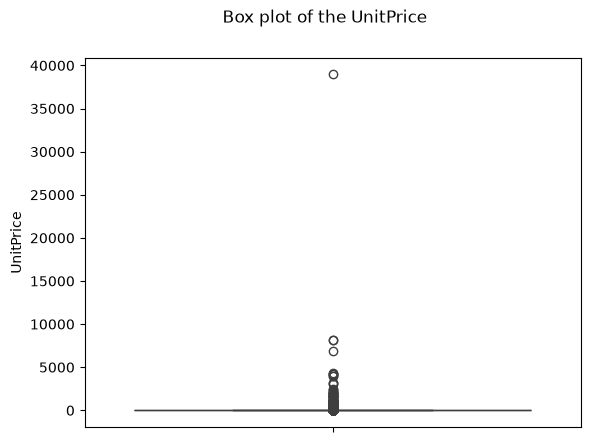

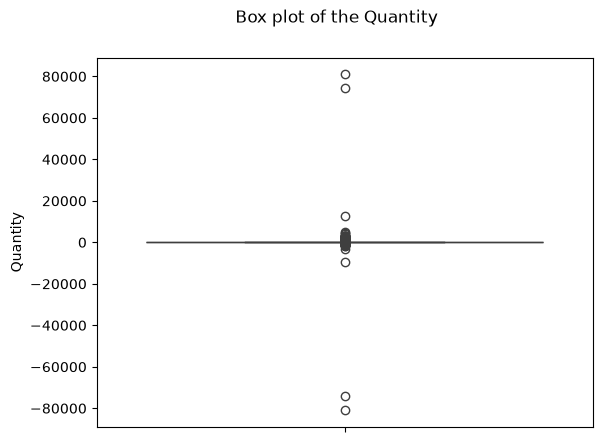

In [193]:
cols = ["UnitPrice", "Quantity"]
for col in cols:
    g = sns.boxplot(
        customer[col],
    )
    g.figure.suptitle(f"Box plot of the {col}")
    plt.show()

In [194]:
for col in cols:
    print(col)
    print(customer.loc[customer[col].nlargest(n=10).index])

UnitPrice
       InvoiceNo StockCode Description  Quantity         InvoiceDate  \
222681   C556445         M      Manual        -1 2011-06-10 15:31:00   
173277   C551685      POST     POSTAGE        -1 2011-05-03 12:51:00   
173382    551697      POST     POSTAGE         1 2011-05-03 13:46:00   
173391   C551699         M      Manual        -1 2011-05-03 14:12:00   
268027   C560372         M      Manual        -1 2011-07-18 12:26:00   
422351    573077         M      Manual         1 2011-10-27 14:13:00   
422375   C573079         M      Manual        -2 2011-10-27 14:15:00   
422376    573080         M      Manual         1 2011-10-27 14:20:00   
406404   C571750         M      Manual        -1 2011-10-19 11:16:00   
406406    571751         M      Manual         1 2011-10-19 11:18:00   

        UnitPrice  CustomerID         Country  
222681   38970.00     15098.0  United Kingdom  
173277    8142.75     16029.0  United Kingdom  
173382    8142.75     16029.0  United Kingdom  
17339

We can see that most of the problematic rows in Unit price nlargest has either business stock code or is canceled. Either way we won't see them in analysis. However, Quantity does not have these problems and look just as large orders.I want to investigate mb these orders were canceled after.

In [195]:
df[df["InvoiceNo"].astype(str).isin(["C581484", "C541433", "C578841"])]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


Two largest quantities were canceled few minutes later. Third observation was not canceled. So i think to drop only 2 highest rows.

Last thing i want to check is date distribution

<Axes: xlabel='InvoiceDate', ylabel='Count'>

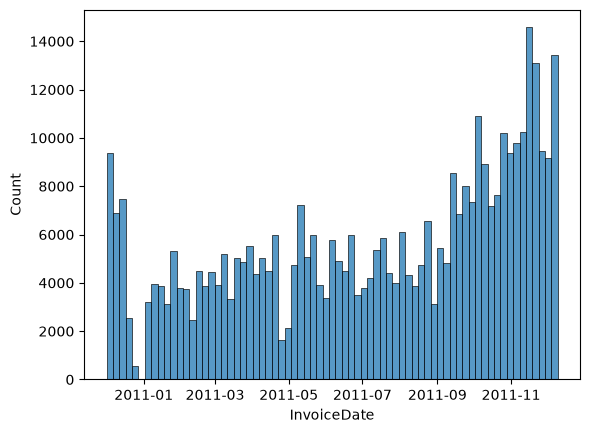

In [196]:
sns.histplot(customer["InvoiceDate"])

Date distribution looks good but there are a gap during dec and january. I think it's just a period when company did not worked.

## What to do in preprocessing

For RFM I only need CustomerID, InvoiceNo, InvoiceDate, Quantity and UnitPrice. Description, StockCode and Country do not build R, F or M, so I did not look at them closely. I used StockCode only to find service codes and Description only to understand what these codes mean.

1. Drop rows with missing CustomerID. There are 135080 of them and they are guest purchases, but to perform RFM clustering I need CustomerID to group by.
2. Transform CustomerID from float to int.
3. Drop service stock codes: POST, M, DOT, D, CRUK, C2, BANK CHARGES. These codes refer to shipping prices and other fees, not real orders. PADS is a real product that they sell, so I will not drop it.
4. Drop 5225 duplicates. All of them are just same entries of one row, so it is safe.
5. Do not drop cancellations, subtract them. All negative quantity rows are cancellations, and dropping them would be a mistake because a cancelled order gives a false monetary value for many customers.
6. Keep rows where UnitPrice is 0. There are 40 of them and I think this is caused by promo actions, gifts or replacement of the product.
7. Drop 2 orders with the highest quantity together with their cancellations. Both of them were cancelled a few minutes later, so I remove the order and the cancellation as a pair.
